<a href="https://colab.research.google.com/github/ankushyadav1280/Lung-Cancer-Project/blob/main/Lung_Cancer_Detection_Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
import os

base_dir = "/content/Lung_Cancer_Project"

folders = [
    "data",
    "metadata",
    "patches",
    "models",
    "results"
]

os.makedirs(base_dir, exist_ok=True)

for folder in folders:
    os.makedirs(os.path.join(base_dir, folder), exist_ok=True)

print("Project folders created successfully!")
print(os.listdir(base_dir))

Project folders created successfully!
['models', 'patches', 'results', 'metadata', 'data']


In [ ]:
import requests
import os

metadata_dir = "/content/Lung_Cancer_Project/metadata"
os.makedirs(metadata_dir, exist_ok=True)

url = "https://zenodo.org/records/3723295/files/annotations.csv?download=1"

response = requests.get(url)

print("Download status:", response.status_code)
print("Downloaded size:", len(response.content), "bytes")

with open(f"{metadata_dir}/annotations.csv", "wb") as file:
    file.write(response.content)

print("annotations.csv saved successfully!")

Download status: 200
Downloaded size: 136986 bytes
annotations.csv saved successfully!


In [ ]:
import pandas as pd

annotations_path = "/content/Lung_Cancer_Project/metadata/annotations.csv"

annotations = pd.read_csv(annotations_path)

print("Annotations shape:", annotations.shape)
print("\nColumns:")
print(annotations.columns.tolist())

print("\nFirst 5 rows:")
display(annotations.head())


Annotations shape: (1186, 5)

Columns:
['seriesuid', 'coordX', 'coordY', 'coordZ', 'diameter_mm']

First 5 rows:


,seriesuid,coordX,coordY,coordZ,diameter_mm
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,-128.699421,-175.319272,-298.387506,5.651471
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,103.783651,-211.925149,-227.121250,4.224708
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.100398138793...,69.639017,-140.944586,876.374496,5.786348
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,-24.013824,192.102405,-391.081276,8.143262
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.100621383016...,2.441547,172.464881,-405.493732,18.545150


In [ ]:
import requests
import os

metadata_dir = "/content/Lung_Cancer_Project/metadata"

url = "https://zenodo.org/records/3723295/files/candidates_V2.zip?download=1"

response = requests.get(url)

print("Status:", response.status_code)
print("Size:", len(response.content), "bytes")

zip_path = f"{metadata_dir}/candidates_V2.zip"

with open(zip_path, "wb") as file:
    file.write(response.content)

print("candidates_V2.zip downloaded successfully!")

Status: 200
Size: 11439452 bytes
candidates_V2.zip downloaded successfully!


In [ ]:
import zipfile
import os

zip_path = "/content/Lung_Cancer_Project/metadata/candidates_V2.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/Lung_Cancer_Project/metadata")

print("Candidates extracted successfully!")

print(os.listdir("/content/Lung_Cancer_Project/metadata"))

Candidates extracted successfully!
['candidates_V2.zip', 'annotations.csv', 'candidates_V2.csv']


In [ ]:

candidates_path = "/content/Lung_Cancer_Project/metadata/candidates_V2.csv"

candidates = pd.read_csv(candidates_path)

print("Candidates shape:", candidates.shape)

print("\nColumns:")
print(candidates.columns.tolist())

display(candidates.head())

Candidates shape: (754975, 5)

Columns:
['seriesuid', 'coordX', 'coordY', 'coordZ', 'class']


,seriesuid,coordX,coordY,coordZ,class
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,68.420000,-74.480000,-288.700000,0
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,-95.209361,-91.809406,-377.426350,0
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,-24.766755,-120.379294,-273.361539,0
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,-63.080000,-65.740000,-344.240000,0
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,52.946688,-92.688873,-241.067872,0


In [ ]:

candidates_path = "/content/Lung_Cancer_Project/metadata/candidates_V2.csv"

candidates = pd.read_csv(candidates_path)

print("Candidates shape:", candidates.shape)

print("\nColumns:")
print(candidates.columns.tolist())

display(candidates.head())

Candidates shape: (754975, 5)

Columns:
['seriesuid', 'coordX', 'coordY', 'coordZ', 'class']


,seriesuid,coordX,coordY,coordZ,class
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,68.420000,-74.480000,-288.700000,0
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,-95.209361,-91.809406,-377.426350,0
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,-24.766755,-120.379294,-273.361539,0
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,-63.080000,-65.740000,-344.240000,0
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.100225287222...,52.946688,-92.688873,-241.067872,0


In [ ]:
!pip install -q SimpleITK

import SimpleITK as sitk

print("SimpleITK ready!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 19.3 MB/s eta 0:00:00
SimpleITK ready!


In [ ]:
import os

data_dir = "/content/Lung_Cancer_Project/data"
os.makedirs(data_dir, exist_ok=True)

%cd /content/Lung_Cancer_Project/data

!wget -c -O subset0.zip \
"https://zenodo.org/records/3723295/files/subset0.zip?download=1"

/content/Lung_Cancer_Project/data
--2026-10-13 06:05:24--  https://zenodo.org/records/3723295/files/subset0.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.52.235, 188.184.103.118, 188.185.43.153, ...
Connecting to zenodo.org (zenodo.org)|137.138.52.235|:443... connected.
HTTP request sent, awaiting response... 206 PARTIAL_CONTENT
Length: 6811924508 (6.3G), 6116985896 (5.7G) remaining [application/octet-stream]
Saving to: ‘subset0.zip’

subset0.zip          16%[++>                 ]   1.04G  --.-KB/s    in 5m 14s  

2026-10-13 06:10:49 (1.28 MB/s) - Connection closed at byte 1116874168. Retrying.

--2026-10-13 06:10:50--  (try: 2)  https://zenodo.org/records/3723295/files/subset0.zip?download=1
Connecting to zenodo.org (zenodo.org)|137.138.52.235|:443... connected.
HTTP request sent, awaiting response... 206 PARTIAL_CONTENT
Length: 6811924508 (6.3G), 5695050340 (5.3G) remaining [application/octet-stream]
Saving to: ‘subset0.zip’

subset0.zip         100%[+++================

In [ ]:
import zipfile
import os

zip_path = "/content/Lung_Cancer_Project/data/subset0.zip"
extract_dir = "/content/Lung_Cancer_Project/data/subset0"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_dir)

print("Extraction complete!")
print("Number of files:", len(os.listdir(extract_dir)))
print("Sample files:", os.listdir(extract_dir)[:10])


Extraction complete!
Number of files: 1
Sample files: ['subset0']


In [ ]:
import os

folder_path = "/content/Lung_Cancer_Project/data/subset0/subset0"

print("Folder exists:", os.path.exists(folder_path))

if os.path.exists(folder_path):
    files = os.listdir(folder_path)

    print("Total files:", len(files))
    print("First 15 files:")
    print(files[:15])
else:
    print("Check the folder structure:")
    print(os.listdir("/content/Lung_Cancer_Project/data/subset0"))

Folder exists: True
Total files: 178
First 15 files:
['1.3.6.1.4.1.14519.5.2.1.6279.6001.334517907433161353885866806005.raw', '1.3.6.1.4.1.14519.5.2.1.6279.6001.334517907433161353885866806005.mhd', '1.3.6.1.4.1.14519.5.2.1.6279.6001.213140617640021803112060161074.mhd', '1.3.6.1.4.1.14519.5.2.1.6279.6001.525937963993475482158828421281.raw', '1.3.6.1.4.1.14519.5.2.1.6279.6001.303421828981831854739626597495.raw', '1.3.6.1.4.1.14519.5.2.1.6279.6001.905371958588660410240398317235.raw', '1.3.6.1.4.1.14519.5.2.1.6279.6001.249530219848512542668813996730.raw', '1.3.6.1.4.1.14519.5.2.1.6279.6001.144438612068946916340281098509.raw', '1.3.6.1.4.1.14519.5.2.1.6279.6001.139713436241461669335487719526.mhd', '1.3.6.1.4.1.14519.5.2.1.6279.6001.302134342469412607966016057827.mhd', '1.3.6.1.4.1.14519.5.2.1.6279.6001.905371958588660410240398317235.mhd', '1.3.6.1.4.1.14519.5.2.1.6279.6001.269689294231892620436462818860.mhd', '1.3.6.1.4.1.14519.5.2.1.6279.6001.404364125369979066736354549484.mhd', '1.3.6.1.4

In [ ]:
import os
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt

ct_folder = "/content/Lung_Cancer_Project/data/subset0/subset0"

mhd_files = [
    f for f in os.listdir(ct_folder)
    if f.endswith(".mhd")
]

print("Total CT scans:", len(mhd_files))

if mhd_files:
    ct_path = os.path.join(ct_folder, mhd_files[0])
    image = sitk.ReadImage(ct_path)
    ct_array = sitk.GetArrayFromImage(image)

    print("Selected scan:", mhd_files[0])
    print("Image dimensions (X, Y, Z):", image.GetSize())
    print("Array shape (Z, Y, X):", ct_array.shape)
    print("Pixel intensity range:", ct_array.min(), "to", ct_array.max())
else:
    print("No MHD files found. Check the dataset folder.")


Total CT scans: 89
Selected scan: 1.3.6.1.4.1.14519.5.2.1.6279.6001.334517907433161353885866806005.mhd
Image dimensions (X, Y, Z): (512, 512, 280)
Array shape (Z, Y, X): (280, 512, 512)
Pixel intensity range: -1000 to 3000


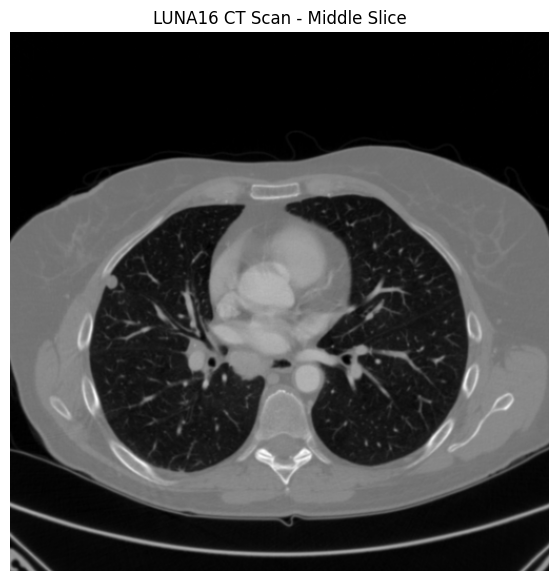

In [ ]:
middle_slice = ct_array.shape[0] // 2

plt.figure(figsize=(7, 7))
plt.imshow(ct_array[middle_slice], cmap="gray")
plt.title("LUNA16 CT Scan - Middle Slice")
plt.axis("off")
plt.show()

In [ ]:

import os

metadata_dir = "/content/Lung_Cancer_Project/metadata"

print("Metadata folder exists:", os.path.exists(metadata_dir))

if os.path.exists(metadata_dir):
    print("Files in metadata folder:")
    print(os.listdir(metadata_dir))

Metadata folder exists: True
Files in metadata folder:
['candidates_V2.zip', 'annotations.csv', 'candidates_V2.csv']


In [ ]:
import os
import pandas as pd

base_dir = "/content/Lung_Cancer_Project"
ct_folder = os.path.join(base_dir, "data/subset0/subset0")
csv_path = os.path.join(base_dir, "metadata/candidates_V2.csv")

# Available CT scans
mhd_files = [
    f for f in os.listdir(ct_folder)
    if f.endswith(".mhd")
]
available_uids = {os.path.splitext(f)[0] for f in mhd_files}

# Load candidate labels
candidates = pd.read_csv(csv_path)

print("Total CT scans:", len(available_uids))
print("Total candidates in CSV:", len(candidates))

# Match candidates to downloaded scans
matched = candidates[
    candidates["seriesuid"].isin(available_uids)
].copy()

print("Matched candidates:", len(matched))
print("\nClass distribution:")
print(matched["class"].value_counts().sort_index())

display(matched.head())

Total CT scans: 89
Total candidates in CSV: 754975
Matched candidates: 79135

Class distribution:
class
0    78997
1      138
Name: count, dtype: int64


,seriesuid,coordX,coordY,coordZ,class
11673,1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031...,-66.383107,57.143607,-60.885862,0
11674,1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031...,-132.856859,23.813034,-274.350845,0
11675,1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031...,84.770000,66.170000,-249.880000,0
11676,1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031...,134.805360,29.696241,-268.116009,0
11677,1.3.6.1.4.1.14519.5.2.1.6279.6001.105756658031...,-87.092676,41.722383,-208.831394,0


In [48]:
import pandas as pd

# Positive and negative candidates
positive = matched[matched["class"] == 1]
negative = matched[matched["class"] == 0]

# Reproducible sampling: 1 positive : 3 negatives
n_positive = min(len(positive), 138)
n_negative = min(len(negative), n_positive * 3)

positive_sample = positive.sample(
    n=n_positive, random_state=42
)

negative_sample = negative.sample(
    n=n_negative, random_state=42
)

balanced = pd.concat(
    [positive_sample, negative_sample],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

print("Selected candidates:", len(balanced))
print("\nClass distribution:")
print(balanced["class"].value_counts().sort_index())

display(balanced.head())

Selected candidates: 552

Class distribution:
class
0    414
1    138
Name: count, dtype: int64


,seriesuid,coordX,coordY,coordZ,class
0,1.3.6.1.4.1.14519.5.2.1.6279.6001.111172165674...,84.689102,46.777640,-98.076471,0
1,1.3.6.1.4.1.14519.5.2.1.6279.6001.134996872583...,-69.805313,56.317865,-82.244674,1
2,1.3.6.1.4.1.14519.5.2.1.6279.6001.188376349804...,57.130000,155.000000,-465.040000,0
3,1.3.6.1.4.1.14519.5.2.1.6279.6001.868211851413...,-23.179375,78.056562,-137.037500,1
4,1.3.6.1.4.1.14519.5.2.1.6279.6001.249530219848...,64.298074,18.865673,-182.102837,0


In [52]:
import os
import gc
import numpy as np
import pandas as pd
import SimpleITK as sitk
from PIL import Image
from tqdm.auto import tqdm

base_dir = "/content/Lung_Cancer_Project"
ct_folder = os.path.join(base_dir, "data/subset0/subset0")
csv_path = os.path.join(base_dir, "metadata/selected_candidates.csv")
patch_dir = os.path.join(base_dir, "patches")

os.makedirs(patch_dir, exist_ok=True)
candidates = pd.read_csv(csv_path)

# CT scan paths
scan_paths = {
    os.path.splitext(f)[0]: os.path.join(ct_folder, f)
    for f in os.listdir(ct_folder)
    if f.endswith(".mhd")
}

saved_rows = []
patch_size = 64
half = patch_size // 2

# Process one CT scan at a time
for uid, group in tqdm(
    candidates.groupby("seriesuid"),
    desc="Processing CT scans"
):
    if uid not in scan_paths:
        continue

    image = sitk.ReadImage(scan_paths[uid])
    volume = sitk.GetArrayViewFromImage(image)

    for idx, row in group.iterrows():
        try:
            x, y, z = image.TransformPhysicalPointToIndex((
                float(row["coordX"]),
                float(row["coordY"]),
                float(row["coordZ"])
            ))
        except Exception:
            continue

        if not (0 <= z < volume.shape[0]
                and 0 <= y < volume.shape[1]
                and 0 <= x < volume.shape[2]):
            continue

        y1, y2 = y-half, y+half
        x1, x2 = x-half, x+half

        if y1 < 0 or x1 < 0:
            continue
        if y2 > volume.shape[1] or x2 > volume.shape[2]:
            continue

        # Copy only this small 2D patch
        patch = np.array(volume[z, y1:y2, x1:x2])

        patch = np.clip(patch, -1000, 400)
        patch = ((patch + 1000) / 1400 * 255).astype(np.uint8)

        filename = f"patch_{idx:04d}_label_{int(row['class'])}.png"
        Image.fromarray(patch).resize((224, 224)).save(
            os.path.join(patch_dir, filename)
        )

        saved_rows.append({
            "filename": filename,
            "seriesuid": uid,
            "label": int(row["class"])
        })

    # Release each volume before loading the next one
    del volume, image
    gc.collect()

manifest = pd.DataFrame(saved_rows)
manifest_path = os.path.join(
    base_dir, "metadata/patch_manifest.csv"
)
manifest.to_csv(manifest_path, index=False)

print("Patch extraction complete!")
print("Saved patches:", len(manifest))
print("Label distribution:")
print(manifest["label"].value_counts().sort_index())
print("Manifest:", manifest_path)

Processing CT scans:   0%|          | 0/86 [00:00<?, ?it/s]

Patch extraction complete!
Saved patches: 551
Label distribution:
label
0    413
1    138
Name: count, dtype: int64
Manifest: /content/Lung_Cancer_Project/metadata/patch_manifest.csv


In [53]:
import os

base_dir = "/content/Lung_Cancer_Project"

paths = {
    "Selected candidates CSV": os.path.join(
        base_dir, "metadata/selected_candidates.csv"
    ),
    "Candidates CSV": os.path.join(
        base_dir, "metadata/candidates_V2.csv"
    ),
    "CT scan folder": os.path.join(
        base_dir, "data/subset0/subset0"
    ),
    "Patch folder": os.path.join(base_dir, "patches")
}

for name, path in paths.items():
    print(f"\n{name}:")
    print("Exists:", os.path.exists(path))

    if os.path.isdir(path):
        files = os.listdir(path)
        print("File count:", len(files))


Selected candidates CSV:
Exists: True

Candidates CSV:
Exists: True

CT scan folder:
Exists: True
File count: 178

Patch folder:
Exists: True
File count: 551


In [54]:
import os
import pandas as pd

base_dir = "/content/Lung_Cancer_Project"
patch_dir = os.path.join(base_dir, "patches")
candidates = pd.read_csv(
    os.path.join(base_dir, "metadata/selected_candidates.csv")
)

valid = []
for idx, row in candidates.iterrows():
    filename = f"patch_{idx:04d}_label_{int(row['class'])}.png"
    if os.path.exists(os.path.join(patch_dir, filename)):
        valid.append({
            "filename": filename,
            "seriesuid": row["seriesuid"],
            "label": int(row["class"])
        })

manifest = pd.DataFrame(valid)
manifest.to_csv(
    os.path.join(base_dir, "metadata/patch_manifest.csv"),
    index=False
)

print("Verified patches:", len(manifest))
print("Class distribution:")
print(manifest["label"].value_counts().sort_index())
print("Manifest saved successfully!")

Verified patches: 551
Class distribution:
label
0    413
1    138
Name: count, dtype: int64
Manifest saved successfully!


In [55]:
import os
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

base_dir = "/content/Lung_Cancer_Project"
manifest_path = os.path.join(
    base_dir, "metadata/patch_manifest.csv"
)

manifest = pd.read_csv(manifest_path)

# First: 80% train+validation, 20% test
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
trainval_idx, test_idx = next(
    split1.split(manifest, groups=manifest["seriesuid"])
)

trainval = manifest.iloc[trainval_idx].reset_index(drop=True)
test = manifest.iloc[test_idx].reset_index(drop=True)

# Second: split remaining data into train and validation
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
train_idx, val_idx = next(
    split2.split(trainval, groups=trainval["seriesuid"])
)

train = trainval.iloc[train_idx].reset_index(drop=True)
val = trainval.iloc[val_idx].reset_index(drop=True)

# Save splits
metadata_dir = os.path.join(base_dir, "metadata")
train.to_csv(os.path.join(metadata_dir, "train.csv"), index=False)
val.to_csv(os.path.join(metadata_dir, "validation.csv"), index=False)
test.to_csv(os.path.join(metadata_dir, "test.csv"), index=False)

for name, df in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"\n{name} patches: {len(df)}")
    print("Unique CT scans:", df["seriesuid"].nunique())
    print("Labels:")
    print(df["label"].value_counts().sort_index())

# Verify there is no scan overlap
assert set(train.seriesuid).isdisjoint(set(val.seriesuid))
assert set(train.seriesuid).isdisjoint(set(test.seriesuid))
assert set(val.seriesuid).isdisjoint(set(test.seriesuid))

print("\nNo CT scan overlap. Split files saved successfully!")


Train patches: 351
Unique CT scans: 54
Labels:
label
0    263
1     88
Name: count, dtype: int64

Validation patches: 92
Unique CT scans: 14
Labels:
label
0    75
1    17
Name: count, dtype: int64

Test patches: 108
Unique CT scans: 18
Labels:
label
0    75
1    33
Name: count, dtype: int64

No CT scan overlap. Split files saved successfully!


In [56]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from tqdm.auto import tqdm

base_dir = "/content/Lung_Cancer_Project"
patch_dir = os.path.join(base_dir, "patches")
metadata_dir = os.path.join(base_dir, "metadata")

def load_images(csv_name):
    df = pd.read_csv(os.path.join(metadata_dir, csv_name))
    images, labels = [], []

    for _, row in tqdm(df.iterrows(), total=len(df), desc=csv_name):
        path = os.path.join(patch_dir, row["filename"])

        with Image.open(path) as img:
            img = img.convert("RGB").resize((224, 224))
            images.append(np.asarray(img, dtype=np.float32))

        labels.append(int(row["label"]))

    X = np.array(images, dtype=np.float32)
    y = np.array(labels, dtype=np.int32)

    return X, y

X_train, y_train = load_images("train.csv")
X_val, y_val = load_images("validation.csv")
X_test, y_test = load_images("test.csv")

print("\nDataset shapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "y_val:", y_val.shape)
print("X_test:", X_test.shape, "y_test:", y_test.shape)

print("\nImage pixel range:", X_train.min(), "to", X_train.max())
print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

train.csv:   0%|          | 0/351 [00:00<?, ?it/s]

validation.csv:   0%|          | 0/92 [00:00<?, ?it/s]

test.csv:   0%|          | 0/108 [00:00<?, ?it/s]


Dataset shapes:
X_train: (351, 224, 224, 3) y_train: (351,)
X_val: (92, 224, 224, 3) y_val: (92,)
X_test: (108, 224, 224, 3) y_test: (108,)

Image pixel range: 0.0 to 255.0
TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


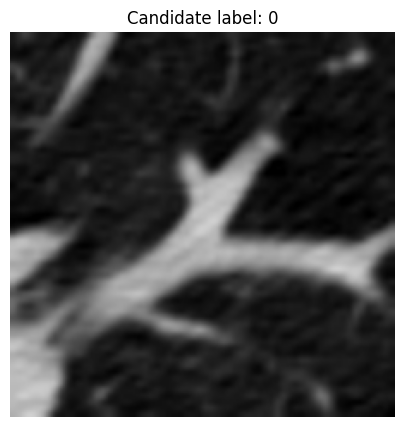

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(X_train[0].astype("uint8"))
plt.title(f"Candidate label: {y_train[0]}")
plt.axis("off")
plt.show()

171317808/171317808 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 45s 554ms/step - accuracy: 0.5014 - loss: 0.8806 - val_accuracy: 0.7500 - val_loss: 0.4963
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.6952 - loss: 0.5630 - val_accuracy: 0.7935 - val_loss: 0.4482
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.7749 - loss: 0.4930 - val_accuracy: 0.7283 - val_loss: 0.5454
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 7s 106ms/step - accuracy: 0.7521 - loss: 0.4766 - val_accuracy: 0.8261 - val_loss: 0.4211
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 110ms/step - accuracy: 0.7920 - loss: 0.4137 - val_accuracy: 0.8804 - val_loss: 0.3421
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 112ms/step - accuracy: 0.8519 - loss: 0.3660 - val_accuracy: 0.8696 - val_loss: 0.3049
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.8775 - loss: 0.3517 - val_accuracy: 0.8370 - val_loss: 0.3691
Epoch 8/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step 

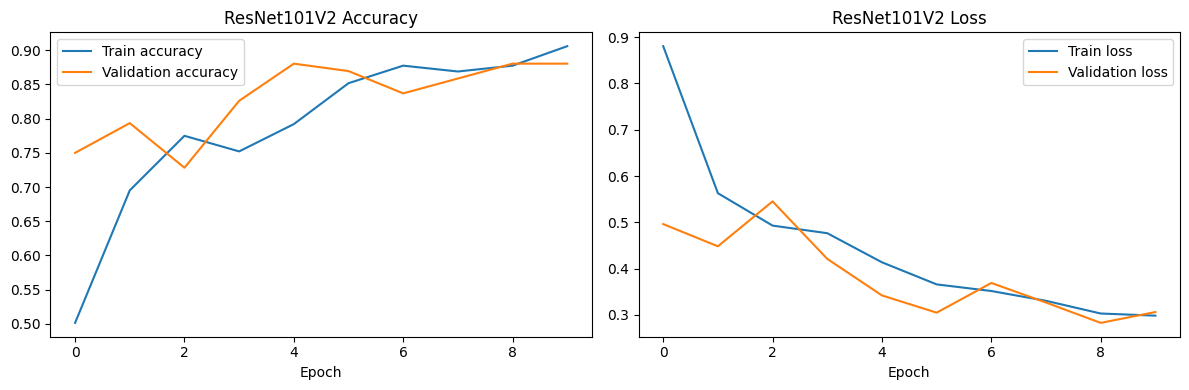

Best validation accuracy: 0.8804
Model and results saved.


In [58]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

base_dir = "/content/Lung_Cancer_Project"
results_dir = os.path.join(base_dir, "results")
models_dir = os.path.join(base_dir, "models")
os.makedirs(results_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

# Check that Step 29 variables exist
assert "X_train" in globals(), "Run Step 29 first."
assert "X_val" in globals(), "Run Step 29 first."
assert "X_test" in globals(), "Run Step 29 first."

# Class weights help with class imbalance
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))

# ResNet101V2 preprocessing expects pixels in the 0-255 range
preprocess = tf.keras.applications.resnet_v2.preprocess_input

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
).shuffle(len(y_train), seed=42).batch(8).map(
    lambda x, y: (preprocess(x), y),
    num_parallel_calls=1
).prefetch(1)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
).batch(8).map(
    lambda x, y: (preprocess(x), y),
    num_parallel_calls=1
).prefetch(1)

# Load pretrained model
base_model = tf.keras.applications.ResNet101V2(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(models_dir, "resnet101v2_best.keras"),
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)

# Save training history and plot
pd = __import__("pandas")
pd.DataFrame(history.history).to_csv(
    os.path.join(results_dir, "resnet101v2_history.csv"),
    index=False
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("ResNet101V2 Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("ResNet101V2 Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(results_dir, "resnet101v2_accuracy_loss.png"),
    dpi=150
)
plt.show()

print("Best validation accuracy:",
      round(max(history.history["val_accuracy"]), 4))
print("Model and results saved.")

27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step
Test Accuracy: 0.8611
Precision: 0.9091
Recall: 0.6061
F1-score: 0.7273

Classification Report:
                      precision    recall  f1-score   support

Non-nodule candidate       0.85      0.97      0.91        75
    Nodule candidate       0.91      0.61      0.73        33

            accuracy                           0.86       108
           macro avg       0.88      0.79      0.82       108
        weighted avg       0.87      0.86      0.85       108



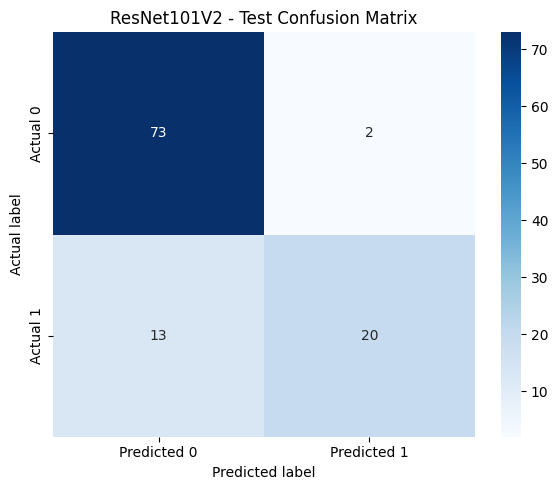

Confusion matrix saved successfully!


In [59]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

base_dir = "/content/Lung_Cancer_Project"
model_path = os.path.join(
    base_dir, "models", "resnet101v2_best.keras"
)

# Load the best saved model
model = tf.keras.models.load_model(model_path)

# Preprocess test images for ResNet101V2
X_test_processed = tf.keras.applications.resnet_v2.preprocess_input(
    X_test.copy()
)

# Predict probabilities and convert to class labels
probabilities = model.predict(
    X_test_processed, batch_size=4, verbose=1
).ravel()

y_pred = (probabilities >= 0.5).astype(int)

# Calculate evaluation metrics
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Non-nodule candidate", "Nodule candidate"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("ResNet101V2 - Test Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()

results_dir = os.path.join(base_dir, "results")
os.makedirs(results_dir, exist_ok=True)
plt.savefig(
    os.path.join(results_dir, "resnet101v2_confusion_matrix.png"),
    dpi=150
)
plt.show()

print("Confusion matrix saved successfully!")

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.5328 - loss: 0.7562 - val_accuracy: 0.6087 - val_loss: 0.6848
Epoch 2/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.6467 - loss: 0.6478 - val_accuracy: 0.4891 - val_loss: 0.7483
Epoch 3/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.7179 - loss: 0.5732 - val_accuracy: 0.4457 - val_loss: 0.7788
Epoch 4/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 130ms/step - accuracy: 0.7066 - loss: 0.5492 - val_accuracy: 0.5978 - val_loss: 0.6549
Epoch 5/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 133ms/step - accuracy: 0.7208 - loss: 0.5186 - val_accuracy: 0.8043 - val_loss: 0.5199
Epoch 6/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.7521 - loss: 0.4997 - val_accuracy: 0.7391 - val_loss: 0.5374
Epoch 7/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - accuracy: 0.7692 - loss: 0.5052 - val_accuracy: 0.6304 - val_loss: 0.6714
Epoch 8/10
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 75ms/step - accur

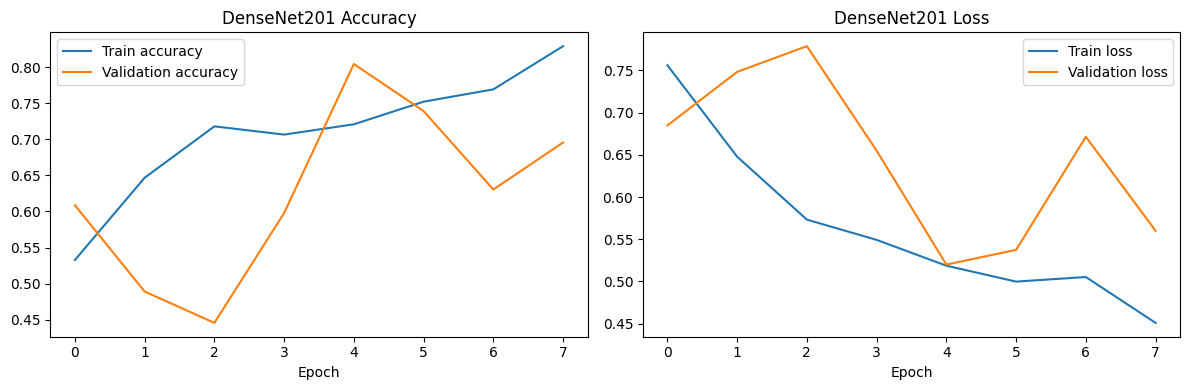

Best validation accuracy: 0.8043
DenseNet201 training complete!


In [60]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

base_dir = "/content/Lung_Cancer_Project"
models_dir = os.path.join(base_dir, "models")
results_dir = os.path.join(base_dir, "results")
os.makedirs(models_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

# Handle class imbalance
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes, weights))

# DenseNet201 preprocessing
preprocess = tf.keras.applications.densenet.preprocess_input

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
).shuffle(len(y_train), seed=42).batch(8).map(
    lambda x, y: (preprocess(x), y),
    num_parallel_calls=1
).prefetch(1)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
).batch(8).map(
    lambda x, y: (preprocess(x), y),
    num_parallel_calls=1
).prefetch(1)

# Load pretrained DenseNet201
base_model = tf.keras.applications.DenseNet201(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)

model_dense = tf.keras.Model(inputs, outputs)
model_dense.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(models_dir, "densenet201_best.keras"),
        monitor="val_loss", save_best_only=True
    )
]

history_dense = model_dense.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)

pd.DataFrame(history_dense.history).to_csv(
    os.path.join(results_dir, "densenet201_history.csv"),
    index=False
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_dense.history["accuracy"], label="Train accuracy")
plt.plot(history_dense.history["val_accuracy"], label="Validation accuracy")
plt.title("DenseNet201 Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_dense.history["loss"], label="Train loss")
plt.plot(history_dense.history["val_loss"], label="Validation loss")
plt.title("DenseNet201 Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(results_dir, "densenet201_accuracy_loss.png"),
    dpi=150
)
plt.show()

print("Best validation accuracy:",
      round(max(history_dense.history["val_accuracy"]), 4))
print("DenseNet201 training complete!")

27/27 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step
DenseNet201 Test Accuracy: 0.787
Precision: 0.7083
Recall: 0.5152
F1-score: 0.5965

Classification Report:
                      precision    recall  f1-score   support

Non-nodule candidate       0.81      0.91      0.86        75
    Nodule candidate       0.71      0.52      0.60        33

            accuracy                           0.79       108
           macro avg       0.76      0.71      0.73       108
        weighted avg       0.78      0.79      0.78       108



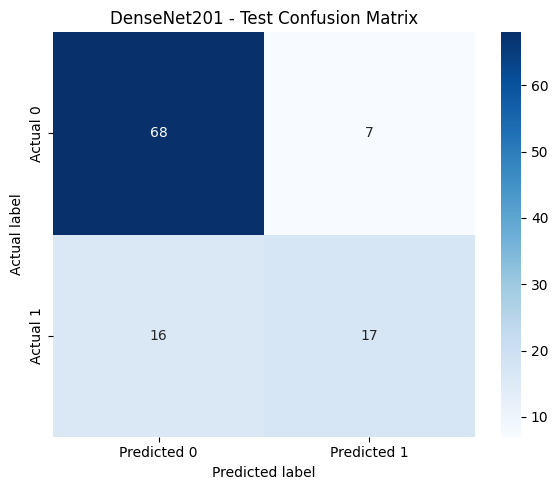

In [61]:
import os
import numpy as np
import tensorflow as tf
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

base_dir = "/content/Lung_Cancer_Project"
model_path = os.path.join(base_dir, "models", "densenet201_best.keras")

model_dense = tf.keras.models.load_model(model_path)

X_test_dense = tf.keras.applications.densenet.preprocess_input(
    X_test.copy()
)

probabilities = model_dense.predict(
    X_test_dense, batch_size=4, verbose=1
).ravel()

y_pred_dense = (probabilities >= 0.5).astype(int)

print("DenseNet201 Test Accuracy:",
      round(accuracy_score(y_test, y_pred_dense), 4))
print("Precision:",
      round(precision_score(y_test, y_pred_dense, zero_division=0), 4))
print("Recall:",
      round(recall_score(y_test, y_pred_dense, zero_division=0), 4))
print("F1-score:",
      round(f1_score(y_test, y_pred_dense, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_dense,
    labels=[0, 1],
    target_names=["Non-nodule candidate", "Nodule candidate"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_dense, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("DenseNet201 - Test Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.tight_layout()

results_dir = os.path.join(base_dir, "results")
plt.savefig(
    os.path.join(results_dir, "densenet201_confusion_matrix.png"),
    dpi=150
)
plt.show()

In [62]:
import os
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.applications import VGG19
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

PROJECT_DIR = "/content/Lung_Cancer_Project"
MODEL_DIR = f"{PROJECT_DIR}/models"
RESULT_DIR = f"{PROJECT_DIR}/results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# VGG19 pretrained base model
base_model = VGG19(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Initially freeze pretrained layers
base_model.trainable = False

# Add classification layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

vgg19_model = Model(inputs=base_model.input, outputs=output)

vgg19_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        f"{MODEL_DIR}/vgg19_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

# VGG19-specific preprocessing
X_train_vgg = tf.keras.applications.vgg19.preprocess_input(
    X_train.copy()
)
X_val_vgg = tf.keras.applications.vgg19.preprocess_input(
    X_val.copy()
)

history_vgg19 = vgg19_model.fit(
    X_train_vgg,
    y_train,
    validation_data=(X_val_vgg, y_val),
    epochs=10,
    batch_size=4,
    callbacks=callbacks,
    verbose=1
)

# Save training history
pd.DataFrame(history_vgg19.history).to_csv(
    f"{RESULT_DIR}/vgg19_history.csv",
    index=False
)

print("VGG19 training complete!")
print("Best validation accuracy:",
      round(max(history_vgg19.history["val_accuracy"]), 4))

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 122ms/step - accuracy: 0.4872 - loss: 1.5139 - val_accuracy: 0.6087 - val_loss: 0.8798
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.6154 - loss: 1.4018 - val_accuracy: 0.6522 - val_loss: 0.8189
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.6040 - loss: 1.1636 - val_accuracy: 0.6739 - val_loss: 0.8011
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 80ms/step - accuracy: 0.6182 - loss: 1.1600 - val_accuracy: 0.6848 - val_loss: 0.7896
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - accuracy: 0.6296 - loss: 1.0830 - val_accuracy: 0.6739 - val_loss: 0.7931
Epoch 6/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - accuracy: 0.5869 - loss: 1.2397 - val_accuracy: 0.6957 - val_loss: 0.7737
Epoch 7/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.6068 - loss: 1.1272 - val_accuracy: 0.6957 - val_loss: 0.7624
Epoch 8/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - accur

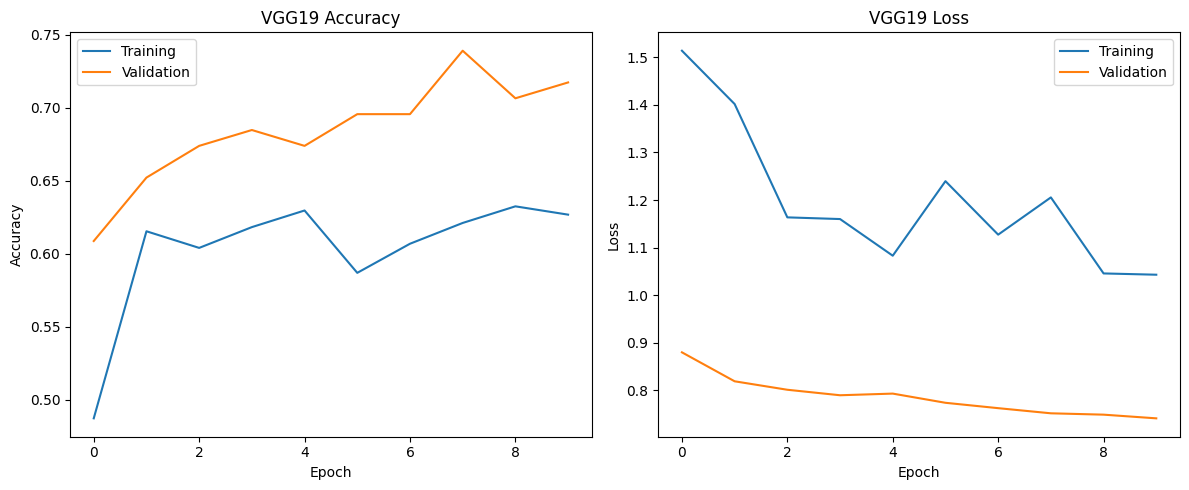

In [63]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_vgg19.history["accuracy"], label="Training")
plt.plot(history_vgg19.history["val_accuracy"], label="Validation")
plt.title("VGG19 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_vgg19.history["loss"], label="Training")
plt.plot(history_vgg19.history["val_loss"], label="Validation")
plt.title("VGG19 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig(
    "/content/Lung_Cancer_Project/results/vgg19_accuracy_loss.png",
    dpi=150
)
plt.show()

27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step
VGG19 Test Results
------------------
Accuracy : 0.6759
Precision: 0.4286
Recall   : 0.1818
F1-score : 0.2553

Classification Report:
                      precision    recall  f1-score   support

Non-nodule candidate       0.71      0.89      0.79        75
    Nodule candidate       0.43      0.18      0.26        33

            accuracy                           0.68       108
           macro avg       0.57      0.54      0.52       108
        weighted avg       0.63      0.68      0.63       108



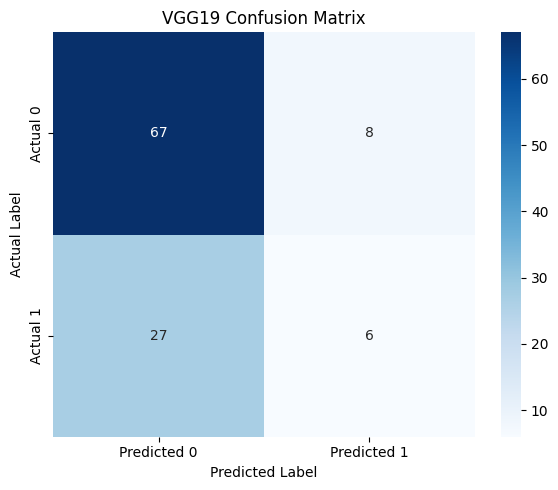

Confusion matrix saved successfully.


In [64]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

PROJECT_DIR = "/content/Lung_Cancer_Project"
MODEL_PATH = f"{PROJECT_DIR}/models/vgg19_best.keras"
RESULT_DIR = f"{PROJECT_DIR}/results"

# Load best saved VGG19 model
vgg19_model = tf.keras.models.load_model(MODEL_PATH)

# VGG19-specific preprocessing
X_test_vgg = tf.keras.applications.vgg19.preprocess_input(
    X_test.copy()
)

# Predict test labels
y_prob = vgg19_model.predict(X_test_vgg, batch_size=4, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)
y_true = np.asarray(y_test).astype(int).ravel()

# Calculate evaluation metrics
print("VGG19 Test Results")
print("------------------")
print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_true, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Non-nodule candidate", "Nodule candidate"],
    zero_division=0
))

# Create and save confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("VGG19 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/vgg19_confusion_matrix.png",
    dpi=150
)
plt.show()

print("Confusion matrix saved successfully.")

In [65]:
import os
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

PROJECT_DIR = "/content/Lung_Cancer_Project"
MODEL_DIR = f"{PROJECT_DIR}/models"
RESULT_DIR = f"{PROJECT_DIR}/results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

# Add classification head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

mobilenet_model = Model(
    inputs=base_model.input,
    outputs=output
)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        f"{MODEL_DIR}/mobilenetv2_best.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

# MobileNetV2 preprocessing
X_train_mob = tf.keras.applications.mobilenet_v2.preprocess_input(
    X_train.copy()
)
X_val_mob = tf.keras.applications.mobilenet_v2.preprocess_input(
    X_val.copy()
)

# Train model
history_mob = mobilenet_model.fit(
    X_train_mob,
    y_train,
    validation_data=(X_val_mob, y_val),
    epochs=10,
    batch_size=4,
    callbacks=callbacks,
    verbose=1
)

# Save training history
pd.DataFrame(history_mob.history).to_csv(
    f"{RESULT_DIR}/mobilenetv2_history.csv",
    index=False
)

print("MobileNetV2 training complete!")
print(
    "Best validation accuracy:",
    round(max(history_mob.history["val_accuracy"]), 4)
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 22s 123ms/step - accuracy: 0.6325 - loss: 0.7047 - val_accuracy: 0.7717 - val_loss: 0.5236
Epoch 2/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6752 - loss: 0.6925 - val_accuracy: 0.7826 - val_loss: 0.5080
Epoch 3/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.6952 - loss: 0.6341 - val_accuracy: 0.7826 - val_loss: 0.5053
Epoch 4/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7037 - loss: 0.6112 - val_accuracy: 0.8043 - val_loss: 0.4822
Epoch 5/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7179 - loss: 0.6105 - val_accuracy: 0.8043 - val_loss: 0.4734
Epoch 6/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7293 - loss: 0.5828 - val_accuracy: 0.8152 - val_loss: 0.4572
Epoch 7/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.7094 - loss: 0.5760 - val_accuracy: 0.8152 - val_loss: 0.4478
Epoch 8/10
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accurac

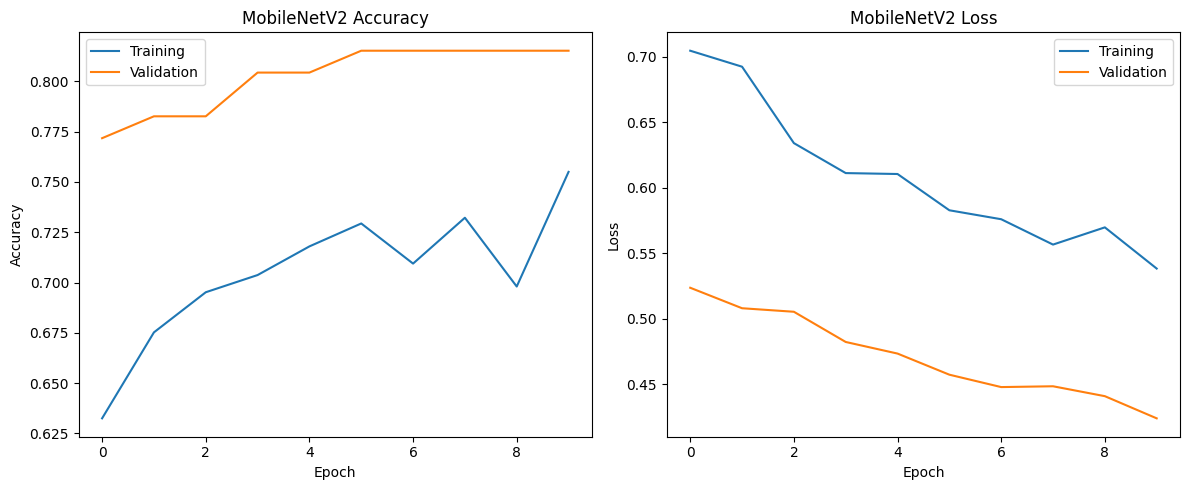

In [66]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_mob.history["accuracy"], label="Training")
plt.plot(history_mob.history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mob.history["loss"], label="Training")
plt.plot(history_mob.history["val_loss"], label="Validation")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig(
    f"{RESULT_DIR}/mobilenetv2_accuracy_loss.png",
    dpi=150
)
plt.show()

27/27 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step
MobileNetV2 Test Results
------------------------
Accuracy : 0.7037
Precision: 0.6
Recall   : 0.0909
F1-score : 0.1579

Classification Report:
                      precision    recall  f1-score   support

Non-nodule candidate       0.71      0.97      0.82        75
    Nodule candidate       0.60      0.09      0.16        33

            accuracy                           0.70       108
           macro avg       0.65      0.53      0.49       108
        weighted avg       0.68      0.70      0.62       108



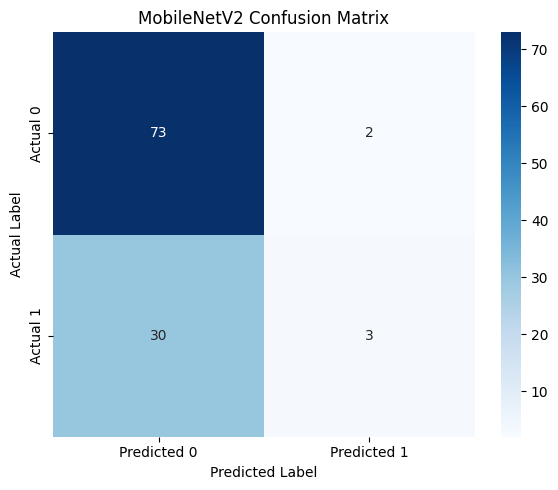

Confusion matrix saved successfully.


In [67]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

PROJECT_DIR = "/content/Lung_Cancer_Project"
MODEL_PATH = f"{PROJECT_DIR}/models/mobilenetv2_best.keras"
RESULT_DIR = f"{PROJECT_DIR}/results"

# Load best saved model
mobilenet_model = tf.keras.models.load_model(MODEL_PATH)

# Preprocess test images for MobileNetV2
X_test_mob = tf.keras.applications.mobilenet_v2.preprocess_input(
    X_test.copy()
)

# Predict
y_prob = mobilenet_model.predict(
    X_test_mob, batch_size=4, verbose=1
).ravel()

y_pred = (y_prob >= 0.5).astype(int)
y_true = np.asarray(y_test).astype(int).ravel()

# Evaluation metrics
print("MobileNetV2 Test Results")
print("------------------------")
print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_true, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Non-nodule candidate", "Nodule candidate"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()

plt.savefig(
    f"{RESULT_DIR}/mobilenetv2_confusion_matrix.png",
    dpi=150
)
plt.show()

print("Confusion matrix saved successfully.")


In [68]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

PROJECT_DIR = "/content/Lung_Cancer_Project"
MODEL_DIR = f"{PROJECT_DIR}/models"
RESULT_DIR = f"{PROJECT_DIR}/results"

os.makedirs(RESULT_DIR, exist_ok=True)

# Model file, model name, and correct preprocessing
model_configs = [
    (
        "ResNet101V2",
        f"{MODEL_DIR}/resnet101v2_best.keras",
        tf.keras.applications.resnet_v2.preprocess_input
    ),
    (
        "DenseNet201",
        f"{MODEL_DIR}/densenet201_best.keras",
        tf.keras.applications.densenet.preprocess_input
    ),
    (
        "VGG19",
        f"{MODEL_DIR}/vgg19_best.keras",
        tf.keras.applications.vgg19.preprocess_input
    ),
    (
        "MobileNetV2",
        f"{MODEL_DIR}/mobilenetv2_best.keras",
        tf.keras.applications.mobilenet_v2.preprocess_input
    )
]

y_true = np.asarray(y_test).astype(int).ravel()
results = []

for name, model_path, preprocess in model_configs:
    if not os.path.exists(model_path):
        print(f"Skipping {name}: model file not found.")
        continue

    print(f"\nEvaluating {name}...")

    model = tf.keras.models.load_model(model_path)

    X_processed = preprocess(X_test.copy())
    probabilities = model.predict(
        X_processed, batch_size=4, verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        )
    })

    del model, X_processed, probabilities, predictions
    tf.keras.backend.clear_session()
    gc.collect()

if results:
    comparison = pd.DataFrame(results)
    comparison = comparison.sort_values(
        "F1-Score", ascending=False
    ).reset_index(drop=True)

    comparison.to_csv(
        f"{RESULT_DIR}/model_comparison.csv",
        index=False
    )

    print("\nMODEL COMPARISON — TEST DATA")
    display(comparison.round(4))

    print("\nSaved:", f"{RESULT_DIR}/model_comparison.csv")
else:
    print("No saved model checkpoints were found.")


Evaluating ResNet101V2...

Evaluating DenseNet201...

Evaluating VGG19...

Evaluating MobileNetV2...

MODEL COMPARISON — TEST DATA


,Model,Accuracy,Precision,Recall,F1-Score
0,ResNet101V2,0.8611,0.9091,0.6061,0.7273
1,DenseNet201,0.7870,0.7083,0.5152,0.5965
2,VGG19,0.6759,0.4286,0.1818,0.2553
3,MobileNetV2,0.7037,0.6000,0.0909,0.1579



Saved: /content/Lung_Cancer_Project/results/model_comparison.csv


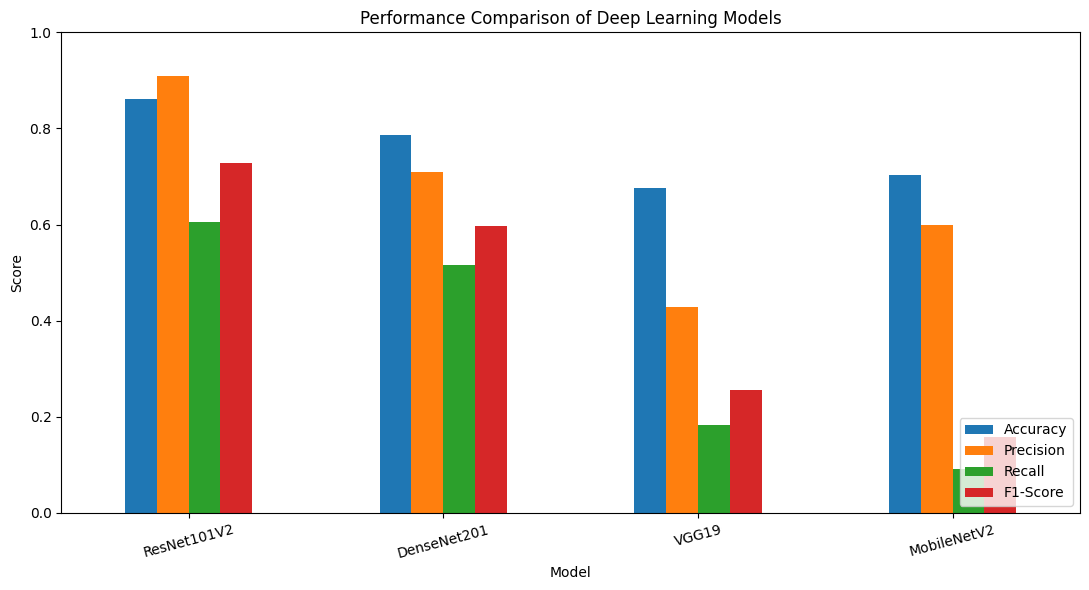

In [69]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison = pd.read_csv(
    "/content/Lung_Cancer_Project/results/model_comparison.csv"
)

ax = comparison.set_index("Model")[metrics].plot(
    kind="bar", figsize=(11, 6)
)

ax.set_title("Performance Comparison of Deep Learning Models")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_xlabel("Model")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "/content/Lung_Cancer_Project/results/model_comparison.png",
    dpi=150
)
plt.show()

Predicting with ResNet101V2
Predicting with DenseNet201
Predicting with MobileNetV2

ENSEMBLE TEST RESULTS
---------------------
Accuracy : 0.7778
Precision: 1.0
Recall   : 0.2727
F1-score : 0.4286

Classification Report:
                      precision    recall  f1-score   support

Non-nodule candidate       0.76      1.00      0.86        75
    Nodule candidate       1.00      0.27      0.43        33

            accuracy                           0.78       108
           macro avg       0.88      0.64      0.65       108
        weighted avg       0.83      0.78      0.73       108



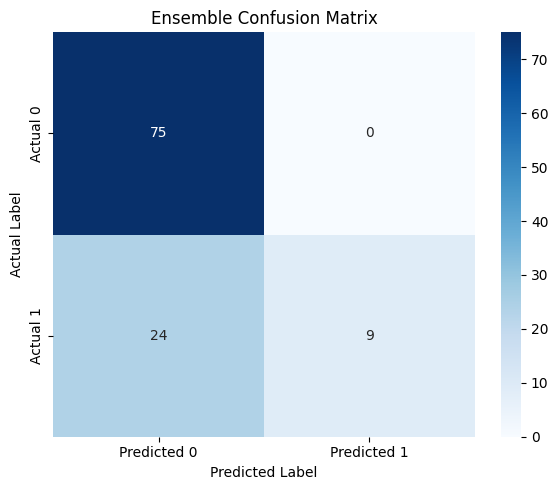

Ensemble evaluation completed.


In [70]:
import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

PROJECT_DIR = "/content/Lung_Cancer_Project"
MODEL_DIR = f"{PROJECT_DIR}/models"
RESULT_DIR = f"{PROJECT_DIR}/results"
os.makedirs(RESULT_DIR, exist_ok=True)

y_true = np.asarray(y_test).astype(int).ravel()

# Model paths and their correct preprocessing functions
ensemble_configs = [
    (
        "ResNet101V2",
        f"{MODEL_DIR}/resnet101v2_best.keras",
        tf.keras.applications.resnet_v2.preprocess_input
    ),
    (
        "DenseNet201",
        f"{MODEL_DIR}/densenet201_best.keras",
        tf.keras.applications.densenet.preprocess_input
    ),
    (
        "MobileNetV2",
        f"{MODEL_DIR}/mobilenetv2_best.keras",
        tf.keras.applications.mobilenet_v2.preprocess_input
    )
]

all_probabilities = []

# Predict sequentially to reduce memory usage
for name, model_path, preprocess in ensemble_configs:
    print("Predicting with", name)

    model = tf.keras.models.load_model(model_path)
    X_processed = preprocess(X_test.copy())

    probabilities = model.predict(
        X_processed, batch_size=4, verbose=0
    ).ravel()

    all_probabilities.append(probabilities)

    del model, X_processed, probabilities
    tf.keras.backend.clear_session()
    gc.collect()

# Soft voting: average predicted probabilities
ensemble_prob = np.mean(
    np.stack(all_probabilities, axis=0), axis=0
)
ensemble_pred = (ensemble_prob >= 0.5).astype(int)

# Evaluate ensemble
print("\nENSEMBLE TEST RESULTS")
print("---------------------")
print("Accuracy :", round(accuracy_score(y_true, ensemble_pred), 4))
print("Precision:", round(precision_score(y_true, ensemble_pred, zero_division=0), 4))
print("Recall   :", round(recall_score(y_true, ensemble_pred, zero_division=0), 4))
print("F1-score :", round(f1_score(y_true, ensemble_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_true,
    ensemble_pred,
    labels=[0, 1],
    target_names=["Non-nodule candidate", "Nodule candidate"],
    zero_division=0
))

# Save predictions
pd.DataFrame({
    "actual_label": y_true,
    "ensemble_probability": ensemble_prob,
    "predicted_label": ensemble_pred
}).to_csv(
    f"{RESULT_DIR}/ensemble_predictions.csv",
    index=False
)

# Confusion matrix
cm = confusion_matrix(y_true, ensemble_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)
plt.title("Ensemble Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    f"{RESULT_DIR}/ensemble_confusion_matrix.png",
    dpi=150
)
plt.show()

print("Ensemble evaluation completed.")